In [26]:
import pandas as pd
import numpy as np

In [27]:
pf = pd.read_csv('/kaggle/input/datasets/shantanudhakadd/bank-customer-churn-prediction/Churn_Modelling.csv')
pf

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [28]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        

/kaggle/input/datasets/shantanudhakadd/bank-customer-churn-prediction/Churn_Modelling.csv


In [29]:
pf.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [30]:
pf.shape

(10000, 14)

In [31]:
pf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [32]:
pf = pf.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1,errors = 'ignore')
pf = pd.get_dummies(pf, columns=['Geography', 'Gender'], drop_first=True)
pf.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [33]:
pf.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [34]:
pf.isnull().sum()

CreditScore          0
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
Geography_Germany    0
Geography_Spain      0
Gender_Male          0
dtype: int64

In [35]:
pf.duplicated().sum()

np.int64(0)

In [36]:
pf['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

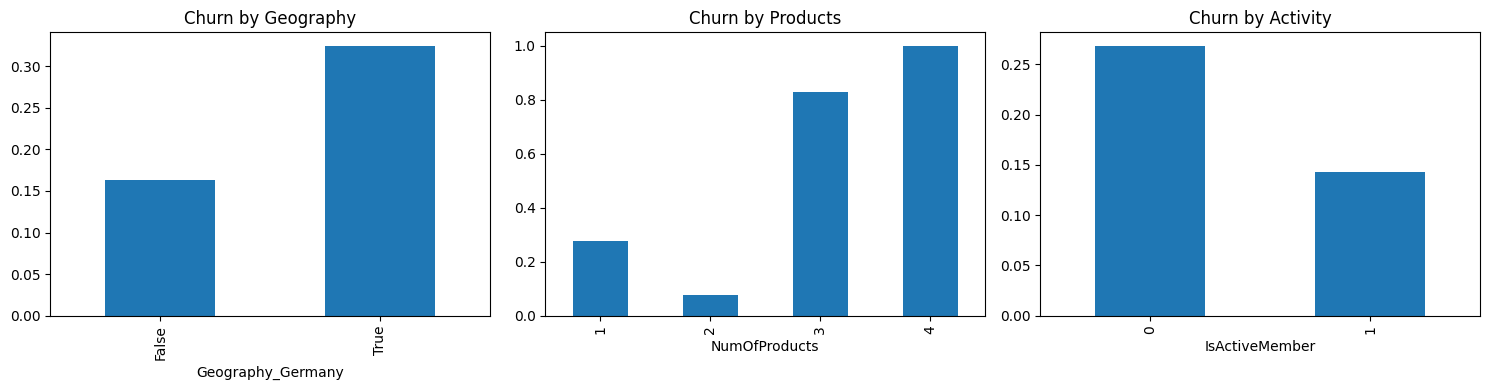

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pf.groupby('Geography_Germany')['Exited'].mean().plot(kind='bar', ax=axes[0], title='Churn by Geography')
pf.groupby('NumOfProducts')['Exited'].mean().plot(kind='bar', ax=axes[1], title='Churn by Products')
pf.groupby('IsActiveMember')['Exited'].mean().plot(kind='bar', ax=axes[2], title='Churn by Activity')
plt.tight_layout()
plt.show()

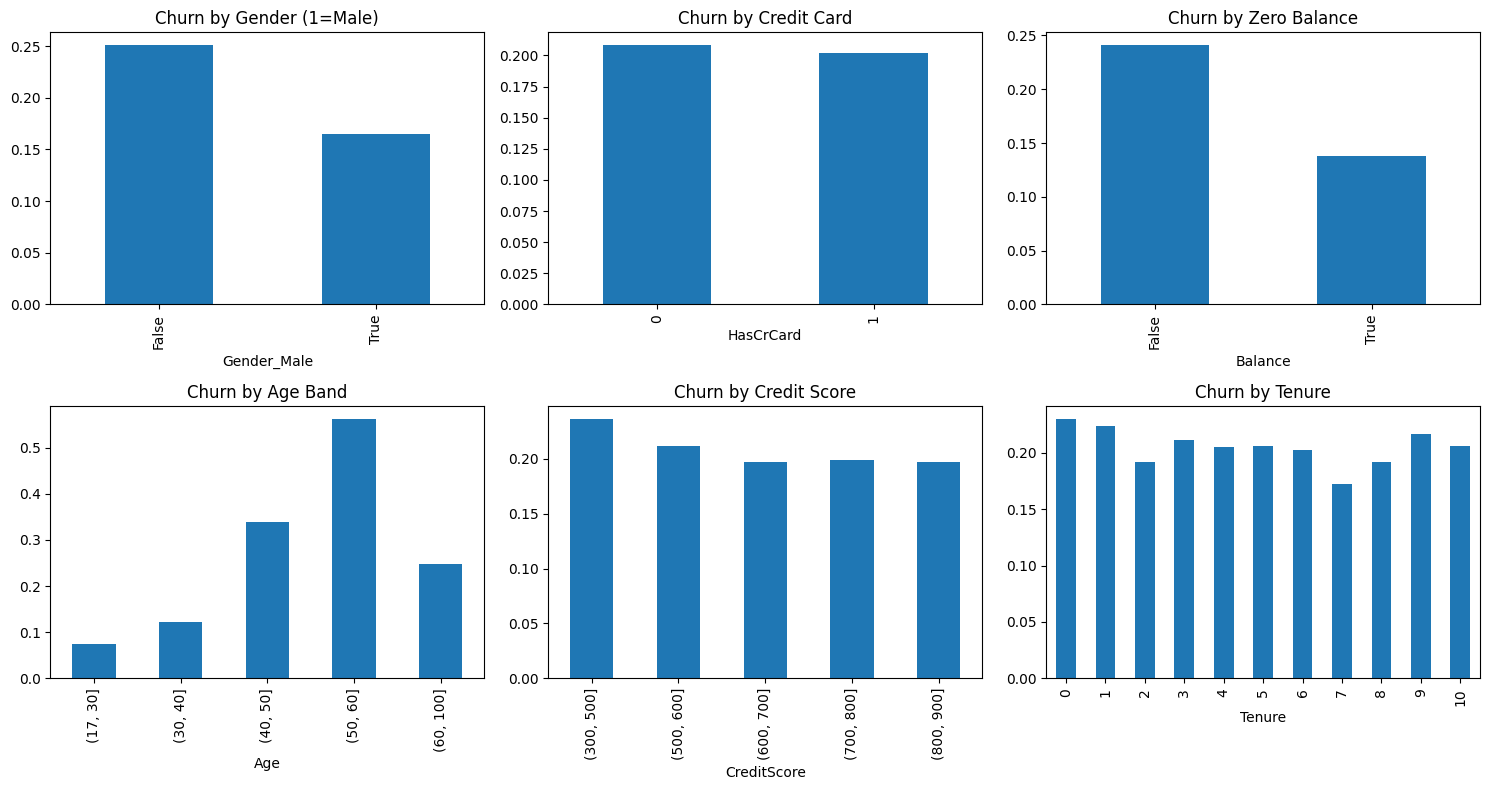

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

pf.groupby('Gender_Male')['Exited'].mean().plot(kind='bar', ax=axes[0,0], title='Churn by Gender (1=Male)')
pf.groupby('HasCrCard')['Exited'].mean().plot(kind='bar', ax=axes[0,1], title='Churn by Credit Card')
pf.groupby(pf['Balance'] == 0)['Exited'].mean().plot(kind='bar', ax=axes[0,2], title='Churn by Zero Balance')
pf.groupby(pd.cut(pf['Age'], [17,30,40,50,60,100]), observed=True)['Exited'].mean().plot(kind='bar', ax=axes[1,0], title='Churn by Age Band')
pf.groupby(pd.cut(pf['CreditScore'], [300,500,600,700,800,900]), observed=True)['Exited'].mean().plot(kind='bar', ax=axes[1,1], title='Churn by Credit Score')
pf.groupby('Tenure')['Exited'].mean().plot(kind='bar', ax=axes[1,2], title='Churn by Tenure')

plt.tight_layout()
plt.show()

In [39]:
from sklearn.model_selection import train_test_split

X = pf.drop('Exited', axis = 1)
y = pf['Exited']

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size = 0.2, random_state = 42,stratify = y)

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

In [41]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [42]:
lr = LogisticRegression(class_weight = 'balanced' , max_iter=1000)
lr.fit(X_train_s,y_train)
lr_pred = lr.predict(X_test_s)
print("Logistic Regression")
print(classification_report(y_test,lr_pred))
print("ROC-AUC:",roc_auc_score(y_test,lr.predict_proba(X_test_s)[:,1]))


Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

ROC-AUC: 0.7771376923919298


In [43]:
rf = RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=42)
rf.fit(X_train,y_train)
rf_pred=rf.predict(X_test)
print("\nRandom Forest")
print(classification_report(y_test,rf_pred))
print("ROC-AUC", roc_auc_score(y_test,rf.predict_proba(X_test)[:,1]))


Random Forest
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.79      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000

ROC-AUC 0.8552797790085926


In [44]:
from sklearn.metrics import classification_report

proba = rf.predict_proba(X_test)[:,1]

for t in[0.5,0.4,0.3,0.25]:
    pred = (proba>=t).astype(int)
    print(f"threshold{t}")
    print(classification_report(y_test,pred,digits=2))
    

threshold0.5
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.79      0.44      0.57       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.74      2000
weighted avg       0.86      0.86      0.85      2000

threshold0.4
              precision    recall  f1-score   support

           0       0.89      0.94      0.91      1593
           1       0.70      0.54      0.61       407

    accuracy                           0.86      2000
   macro avg       0.79      0.74      0.76      2000
weighted avg       0.85      0.86      0.85      2000

threshold0.3
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      1593
           1       0.59      0.65      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.84      0.84  

In [45]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf, X, y, cv=5, scoring='roc_auc')
print(scores.mean(), scores.std())

0.8560773351604454 0.004477932838069567


In [46]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

gb = GradientBoostingClassifier(random_state=42)
scores = cross_val_score(gb, X, y, cv=5, scoring='roc_auc')
print(scores.mean(), scores.std())

0.865577675980912 0.002099862779172447


In [47]:
from sklearn.metrics import classification_report, roc_auc_score

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
proba = gb.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:", roc_auc_score(y_test, proba))

for t in [0.5, 0.4, 0.3, 0.25]:
    pred = (proba >= t).astype(int)
    print(f"Threshold {t}")
    print(classification_report(y_test, pred, digits=2))

Test ROC-AUC: 0.8708307691358538
Threshold 0.5
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.84      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000

Threshold 0.4
              precision    recall  f1-score   support

           0       0.89      0.94      0.92      1593
           1       0.71      0.55      0.62       407

    accuracy                           0.86      2000
   macro avg       0.80      0.75      0.77      2000
weighted avg       0.86      0.86      0.86      2000

Threshold 0.3
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      1593
           1       0.63      0.65      0.64       407

    accuracy                           0.85      2000
   macro avg       0.77      0.78      0.78      2000

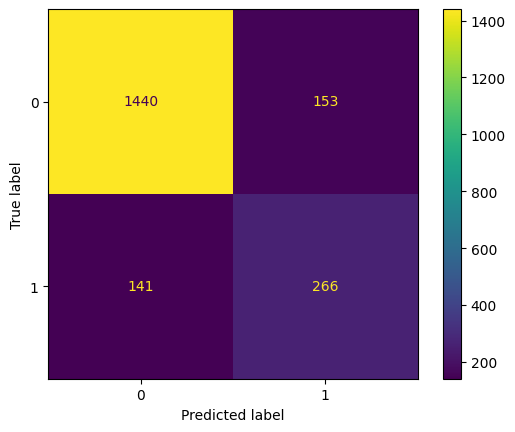

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_03 = (proba >= 0.3).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, pred_03)
plt.show()

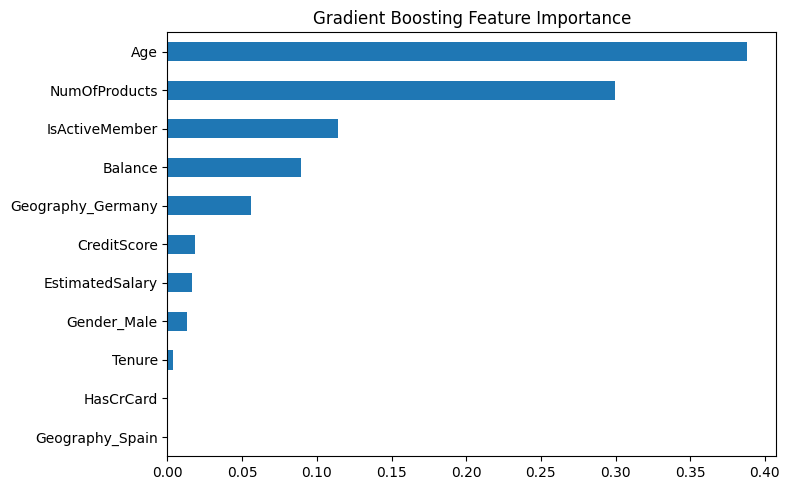

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 5), title='Gradient Boosting Feature Importance')
plt.tight_layout()
plt.show()